# Downsampling Pipeline

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import healpy as hp
import os
import camb
from camb import model, initialpower
from scipy.optimize import minimize
from corner import corner
from minkasi.null_test.estimators import polspice
from minkasi import util as mt
import xqml
from astropy.io import fits

pars = camb.CAMBparams()

In [2]:
lmax_sim = 32
nside_sim = 128
lmax_xqml = 32
nside_xqml = 16

In [3]:
ls_sim = np.arange(2, lmax_sim+1)
ls_xqml = np.arange(2, lmax_xqml+1)

In [4]:
# get power spectra for a given tau
def get_Clhat(tau, lmax, raw_cl=True,
              H0=67, Ombh2=0.024, Omch2=0.12,
              As=2.1e-9, ns=0.965, ks=0.05, 
              kt=0.05, Omk=0, TCMB=2.7255, 
              mnu=0.06, r=0, YHe=0.245400,):
    '''
    Specify tau, and use other known parameters
    '''
    pars.set_cosmology(H0=H0, ombh2=Ombh2, omch2=Omch2, mnu=mnu, omk=Omk, tau=tau, TCMB=TCMB, YHe=YHe)
    pars.InitPower.set_params(As=As, ns=ns, r=r, pivot_scalar=ks, pivot_tensor=kt)
    results = camb.get_results(pars)
    powers = results.get_total_cls(lmax=lmax, CMB_unit='muK', raw_cl=True)
    TT, EE, BB, TE = powers.T
    #ls = np.arange(2, EE.shape[0]) # could add??
    return np.array([TT, EE, BB, TE])

true_tau = 0.054
ls_sim = np.arange(2, lmax_sim+1)
true_spectra_sim = get_Clhat(true_tau, lmax=lmax_sim) # ensemble average power spectrum for higher resolution maps
true_spectra_xqml = get_Clhat(true_tau, lmax=lmax_xqml) # ensemble average power spectrum for xqml

# for plotting
Z = ls_sim*(ls_sim+1)/(2*np.pi)
# plt.semilogx(ls_sim, true_spectra[1][ls_sim]*Z)
# plt.xlabel(r'$\ell$')
# plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell$\,$\mathrm{[\mu K^2]}$')
# plt.title("True CMB EE Spectrum")

In [5]:
import pysm3
import pysm3.units as u

sky = pysm3.Sky(nside=nside_sim, preset_strings=["s0", "d0"], output_unit=u.uK_CMB)

# Convert foregrounds to CMB units
total23 = sky.get_emission(23 * u.GHz)
total93 = sky.get_emission(93 * u.GHz)
total353 = sky.get_emission(353 * u.GHz)

print("ORIGINAL Foreground RMS")
print(f"23 GHz:  {np.std(total23):.2f}")
print(f"93 GHz:  {np.std(total93):.2f}")
print(f"353 GHz: {np.std(total353):.2f}")

total23 = np.array(total23)
total93 = np.array(total93)
total353 = np.array(total353)

# Rotate foregrounds from galactic to celestial (equatorial) coordinates.
# rotate_map_alms handles the (I, Q, U) maps via spin-2 harmonics, so the
# polarization angles are rotated along with the pixels.
rot_gal2cel = hp.Rotator(coord=["G", "C"])
total23 = rot_gal2cel.rotate_map_alms(total23)
total93 = rot_gal2cel.rotate_map_alms(total93)
total353 = rot_gal2cel.rotate_map_alms(total353)

ORIGINAL Foreground RMS
23 GHz:  153.79 uK_CMB
93 GHz:  108.41 uK_CMB
353 GHz: 6125.48 uK_CMB


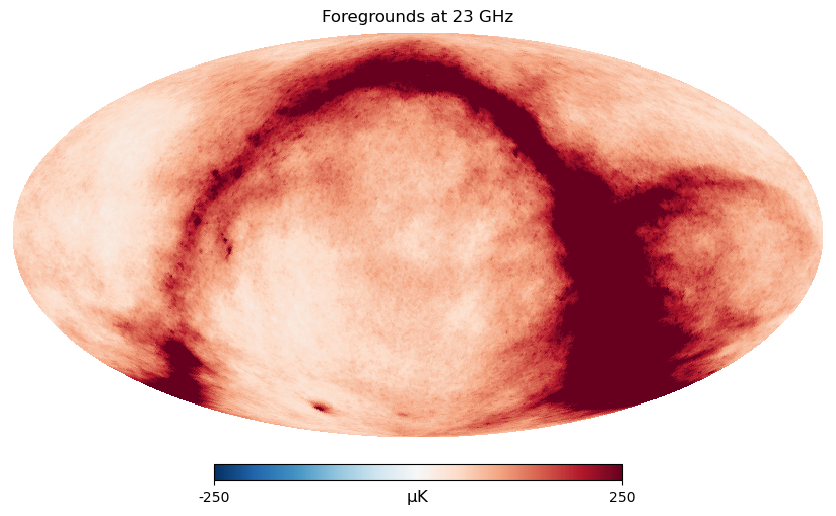

In [6]:
hp.mollview(total23[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='Foregrounds at 23 GHz')  

In [14]:
pix_rad = hp.nside2resol(nside_xqml)  
pix_deg = np.degrees(pix_rad)  # pixel radius in degrees

print(pix_deg *2, pix_deg*3)

7.329037678543799 10.9935565178157


### EE grid set up for xQML

In [38]:
grid_min = 0
grid_max = 0.15
grid_size = 500

tau_coarse_grid = np.linspace(grid_min, grid_max, 100)

EE_coarse_grid = np.array([
    get_Clhat(t, lmax=lmax_xqml)[1]
    for t in tau_coarse_grid
])

from scipy.interpolate import CubicSpline
EE_cubicspline = CubicSpline(
    tau_coarse_grid, 
    EE_coarse_grid, 
    axis=0
)

tau_grid = np.linspace(grid_min, grid_max, grid_size)

EE_grid = EE_cubicspline(tau_grid)

 Check input parameters an Reionization_xe
 function in the Reionization module


In [39]:
DELL = 3
bins = xqml.Bins.fromdeltal(2,lmax_xqml,DELL)
ell_xqml = np.arange(2, lmax_xqml+1)
ell_bins_xqml = bins.lbin
ell_index_xqml = np.array([np.where(ls_xqml == L)[0][0] for L in ell_xqml])
# EE_grid_full_xqml = np.zeros((len(tau_grid), lmax + 1))
# EE_grid_full_xqml[:, ell_xqml] = EE_grid[:, ell_index_xqml]
EE_grid_binned_xqml = bins.bin_spectra(EE_grid, Dl=True)

EE_input_xqml = np.array(true_spectra_xqml[1][:lmax_xqml + 1], copy=True)
EE_input_xqml[ell_xqml] = EE_cubicspline(0.054)[ell_xqml]
clth_xqml = np.array([
    true_spectra_xqml[0][:lmax_xqml + 1],
    EE_input_xqml,
    true_spectra_xqml[2][:lmax_xqml + 1],
    true_spectra_xqml[3][:lmax_xqml + 1]])

In [33]:
def noise_calcs(noise, nside):
    npix = hp.nside2npix(nside)
    solid_angle = hp.nside2pixarea(nside)
    # map sensitivity
    sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)
    Nl = 4*np.pi * sigma_pix**2 / npix
    
    return sigma_pix, npix, Nl

def original_ilc(nside, s, sigma_pix, npix, Nl):
    n = np.random.randn(npix) * sigma_pix

    combined23 = s + total23
    combined93 = s + total93 + n
    combined353 = s + total353

    chat = np.empty((3, npix))
    chat[0] = np.zeros(npix)
    Nl_eff = np.zeros(3)

    for j in (1,2):
        temp_arr_auto = np.array([combined23[j], combined93[j], combined353[j]])
        x0 = np.zeros(len(temp_arr_auto)-1)
        sol = minimize(f, x0, args=(temp_arr_auto))
        a = np.concatenate((sol.x, np.array([1-sum(sol.x)])))
        chat[j] = a.dot(temp_arr_auto)

        Nl_eff[j] = a[1]**2*Nl

    return chat, Nl_eff

def ilc(nside, s, sigma_pix, npix, Nl):
    n = np.random.randn(npix) * sigma_pix

    combined23 = s + total23
    combined93 = s + total93 + n
    combined353 = s + total353

    chat = np.empty((3, npix))
    chat[0] = np.zeros(npix)
    Nl_eff = np.zeros(3)

    maps = np.array([combined23, combined93, combined353])
    qu = maps[:, 1:, :]

    (Q, U), w1, w2 = pilc.method2_foreground_cleaning(qu, pre=pre)
    chat[1] = Q
    chat[2] = U

    return chat, Nl #Nl is wrong here

def generate_maps(noise, nside, foregrounds=True):
    # generates sims with foregrounds
    sigma_pix, npix, Nl = noise_calcs(noise, nside)
    s = hp.synfast(true_spectra_sim, nside, lmax=lmax_sim, new=True, pol=True)

    if foregrounds:
        m1, Nl1 = ilc(nside, s, sigma_pix, npix, Nl)
        m2, Nl2 = ilc(nside, s, sigma_pix, npix, Nl)

        return m1, m2, Nl1, Nl2
    else:
        n1 = np.random.randn(npix) * sigma_pix
        n2 = np.random.randn(npix) * sigma_pix 

        map1 = s + n1
        map2 = s + n2

        return map1, map2, Nl, Nl

def f(a, maps):
    if len(a) == 1:
        coeffs = np.array([a[0], 1-a[0]])
    else:
        coeffs = np.concatenate((a, [1-sum(a)]))
    chat = coeffs.dot(maps)
    return chat.var()

def downgrade_map_with_smoothing(m, fwhm, nside_out=nside_xqml,  **kwargs):
    '''
    fwhm should be in degrees
    '''

    fwhm_rad = np.radians(fwhm)  # Convert fwhm from degrees to radians
    # Antialias a with a Gaussian beam
    m_smooth = hp.smoothing(m, fwhm=fwhm_rad, **kwargs)

    # downgrade it to nside_out
    return hp.ud_grade(m_smooth, nside_out)

## Nl_eff[j] = a[1]**2 * Nl_hi * hp.gauss_beam(fwhm, lmax)**2

### masks

In [ ]:
filename = "/data/users/class/mapmaking_in/input_maps/mask/SRoll2_lowell_f060_nside16_C.fits"

with fits.open(filename) as hdul:
    hdul.info()  # Print information about the HDU list
    for hdu in hdul:
        print(hdu.header.get("COORDSYS"))

Filename: /data/users/class/mapmaking_in/input_maps/mask/SRoll2_lowell_f060_nside16_C.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  xtension      1 BinTableHDU     18   3R x 1C   [1024L]   
None
None


(3072,)
[False False False ... False False False]


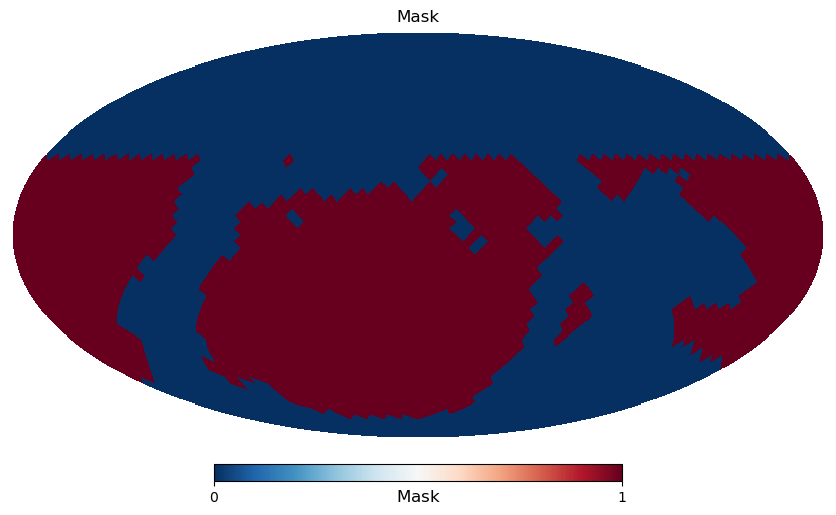

In [15]:
filename = "/data/users/class/mapmaking_in/input_maps/mask/SRoll2_lowell_f060_nside16_C.fits"
m16 = hp.read_map(filename)
mask_class = mt.dec_mask(nside_xqml, [-74, 28], coord='C')
print(m16.shape)
print(m16 & mask_class)

hp.mollview(mask_class & m16, min=0, max=1, unit=r'$\mathrm{Mask}$', cmap='RdBu_r', title='Mask')

In [16]:
filename128 = "/data/users/class/mapmaking_in/input_maps/mask/SRoll2_lowell_f060_nside128_C.fits"
m128 = hp.read_map(filename128)

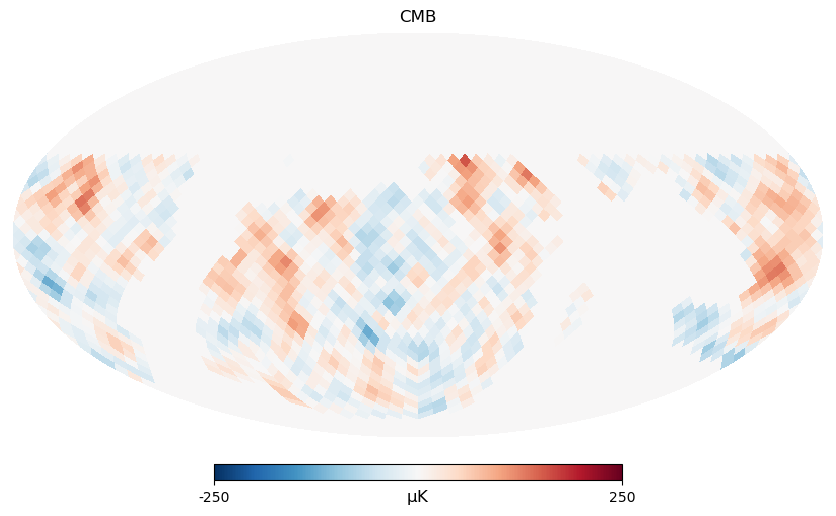

In [12]:
s_test = hp.synfast(true_spectra_xqml, 16, lmax=32, new=True, pol=True)
s_masked = s_test * (mask_class & m)
hp.mollview(s_masked[0], min=-250, max=250, unit=r'$\mathrm{\mu K}$', cmap='RdBu_r', title='CMB')

### running xqml simulations

In [34]:
def simulation_setup(noise, nside=nside_xqml):
    sigma_pix, npix, _ = noise_calcs(noise, nside)

    unmasked_pix = np.count_nonzero(m)
    NoiseVar = (sigma_pix**2 * np.eye(2*unmasked_pix))
    spec = ['EE','BB']

    esti = xqml.xQML(
        m16,
        m16,
        bins,
        clth_xqml,
        NA=NoiseVar,
        NB=NoiseVar,
        lmax=lmax_xqml,
        fwhm=0,
        spec=spec,
        pixwin=False
    )

    covariance_full = esti.get_covariance() 
    covariance_EE = covariance_full[0:len(ell_bins_xqml), 0:len(ell_bins_xqml)]
    icovariance_EE = np.linalg.inv(covariance_EE)
    return esti, icovariance_EE

def create_mask (filename, class_mask=True, nside=nside_xqml):
    m = hp.read_map(filename)
    if class_mask:
        mask_class = mt.dec_mask(nside, [-74, 28], coord='C')
        return mask_class & m
    else:
        return m

In [35]:
def run_single_simulation(noise, nside_sim, nside_xqml, fwhm, icovariance_EE, esti, mask, xqml=True):
    # generate sims and foregrounds, then does ILC
    map1, map2, Nl1_high, Nl2_high = generate_maps(noise, nside=nside_sim, foregrounds=True)

    # downgrade maps to nside_xqml with smoothing
    map1_downgraded = downgrade_map_with_smoothing(map1, fwhm, nside_out=nside_xqml)
    map2_downgraded = downgrade_map_with_smoothing(map2, fwhm, nside_out=nside_xqml)

    # apply mask to downgraded maps
    map1_masked = map1_downgraded * mask
    map2_masked = map2_downgraded * mask
    # map1_masked = map1_masked[1:3]  # Q, U
    # map2_masked = map2_masked[1:3]  # Q, U

    if xqml:
        Clhat_cross = esti.get_spectra(map1_masked, map2_masked)[0]

        residual = Clhat_cross[None, :] - EE_grid_binned_xqml        # (ntau, nbins)
        chi2_cross = np.einsum('ti,ij,tj->t', residual, icovariance_EE, residual)  # no logdet: M is fixed

    return tau_grid[np.argmin(chi2_cross)]    

In [36]:
def run_full_simulations(noise, nside_sim, nside_xqml, fwhm, mask, num_simulations):
    tau_estimates = []

    esti, icovariance_EE = simulation_setup(noise, nside_xqml)

    for i in range(num_simulations):
        tau_estimate = run_single_simulation(noise, nside_sim, nside_xqml, fwhm, icovariance_EE, esti, mask, xqml=True)
        tau_estimates.append(tau_estimate)

    return np.array(tau_estimates)

In [40]:
mask = create_mask(filename, class_mask=True, nside=nside_xqml)
taus = run_full_simulations(30, nside_sim,nside_xqml, 9, mask, 10)

xQML
spec: ['EE', 'BB']
nbin: 10
Memset: 2.02 Gb 2 spec 10 bin 2 1843 pix
Construct Pl: 2.0 sec
Construct S: 0.5 sec
Construct El (nl=20): 25.1 sec
Construct Wll (nl=20): 4.7 sec
Construct estimator: 68.2 sec


(array([158.41269841,   0.        ,   0.        ,   0.        ,
        158.41269841,   0.        , 158.41269841, 158.41269841,
          0.        , 316.82539683, 158.41269841, 158.41269841,
          0.        ,   0.        ,   0.        , 158.41269841,
          0.        ,   0.        ,   0.        , 158.41269841]),
 array([0.03907816, 0.03970942, 0.04034068, 0.04097194, 0.04160321,
        0.04223447, 0.04286573, 0.04349699, 0.04412826, 0.04475952,
        0.04539078, 0.04602204, 0.04665331, 0.04728457, 0.04791583,
        0.04854709, 0.04917836, 0.04980962, 0.05044088, 0.05107214,
        0.05170341]),
 <BarContainer object of 20 artists>)

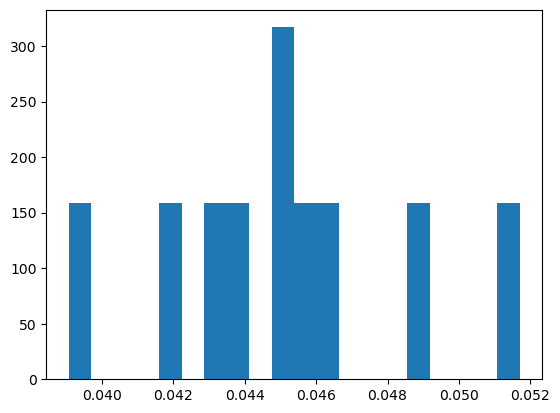

In [41]:
plt.hist(taus, bins=20, density=True)

In [54]:
def sigma_tau_plot(noises, nsim):
    sigma_tau = []
    bias_tau = []

    for n in noises:
        auto = run_full_simulations(n, nside_sim, nside_xqml, 9, mask, nsim)
        sigma_tau.append(auto.std())
        bias_tau.append(auto.mean() - 0.054)
        print(n)

    return np.array(sigma_tau), np.array(bias_tau)

In [56]:
mask = create_mask(filename, class_mask=True, nside=nside_xqml)
noises = np.arange(0,110,10, dtype=float)
noises = np.insert(noises, 0, 0.1)
sigma, bias = sigma_tau_plot(noises, 100)

xQML
spec: ['EE', 'BB']
nbin: 10
Memset: 2.02 Gb 2 spec 10 bin 2 1843 pix
Construct Pl: 2.0 sec
Construct S: 0.6 sec
Construct El (nl=20): 27.5 sec
Construct Wll (nl=20): 4.1 sec
Construct estimator: 85.0 sec
0.1
xQML
spec: ['EE', 'BB']
nbin: 10
Memset: 2.02 Gb 2 spec 10 bin 2 1843 pix
Construct Pl: 2.2 sec
Construct S: 0.4 sec


/home/viviantao1/.local/lib/python3.11/site-packages/xqml/xqml_utils.py:21: LinAlgWarning: Ill-conditioned matrix (rcond=6.85876e-21): result may not be accurate.
  inv = linalg.solve(a, I, assume_a='sym', overwrite_b=True, )


Construct El (nl=20): 20.4 sec
Construct Wll (nl=20): 3.5 sec
Construct estimator: 74.8 sec
0.0
xQML
spec: ['EE', 'BB']
nbin: 10
Memset: 2.02 Gb 2 spec 10 bin 2 1843 pix
Construct Pl: 4.4 sec
Construct S: 0.8 sec
Construct El (nl=20): 23.6 sec
Construct Wll (nl=20): 3.7 sec
Construct estimator: 64.1 sec
10.0
xQML
spec: ['EE', 'BB']
nbin: 10
Memset: 2.02 Gb 2 spec 10 bin 2 1843 pix
Construct Pl: 2.3 sec
Construct S: 0.9 sec
Construct El (nl=20): 23.4 sec
Construct Wll (nl=20): 3.5 sec
Construct estimator: 61.4 sec
20.0
xQML
spec: ['EE', 'BB']
nbin: 10
Memset: 2.02 Gb 2 spec 10 bin 2 1843 pix
Construct Pl: 2.3 sec
Construct S: 0.8 sec
Construct El (nl=20): 22.3 sec
Construct Wll (nl=20): 3.9 sec
Construct estimator: 63.8 sec
30.0
xQML
spec: ['EE', 'BB']
nbin: 10
Memset: 2.02 Gb 2 spec 10 bin 2 1843 pix
Construct Pl: 2.4 sec
Construct S: 0.7 sec
Construct El (nl=20): 26.2 sec
Construct Wll (nl=20): 4.7 sec
Construct estimator: 68.2 sec
40.0
xQML
spec: ['EE', 'BB']
nbin: 10
Memset: 2.02 Gb

In [57]:
import pandas as pd
goal = pd.read_csv("goal_table.csv", names=['noise','sigma_tau'])

goal = goal[goal['noise'] <= 100]

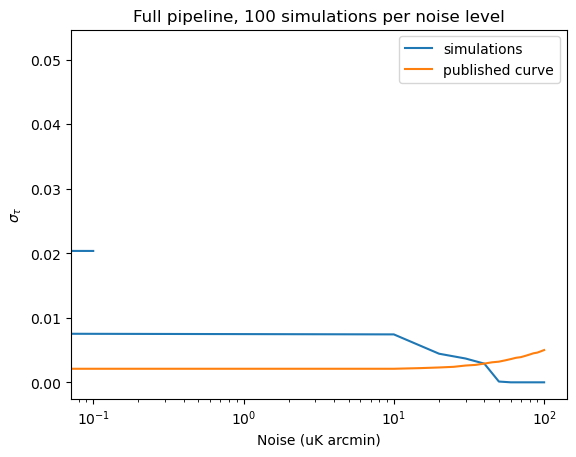

In [58]:
plt.semilogx(noises, sigma, label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Full pipeline, 100 simulations per noise level")
plt.legend()

# testing ILC

In [ ]:

import healpy as hp
import numpy as np


def cmb_spectrum(nside, cl, fwhm_deg=9.0, lmax=None, cutoff=0.0, spin=0):
    lmax = 2 * nside if lmax is None else lmax
    cl = np.atleast_2d(np.asarray(cl, dtype=float))[:, : lmax + 1]
    if spin == 0:
        beam = hp.gauss_beam(np.radians(fwhm_deg), lmax=lmax) * hp.pixwin(nside, lmax=lmax)
    else:
        b = hp.gauss_beam(np.radians(fwhm_deg), lmax=lmax, pol=True)
        beam = np.array([b[:, 1], b[:, 2]]) * hp.pixwin(nside, lmax=lmax, pol=True)[1]
    assert len(cl) == len(np.atleast_2d(beam)), 
    # c = cl * beam**2
    c = cl
    c[:, :2] = 0  # no monopole/dipole
    return c[:, : np.nonzero(c.max(axis=0) >= 1e-3 * cutoff * c.max())[0].max() + 1]


def _analysis(x, lmax):
    if len(x) == 1:
        return [hp.map2alm(x[0], lmax=lmax, iter=0)]
    return hp.map2alm_spin(x, 2, lmax=lmax)


def _synthesis(alms, nside, lmax):
    if len(alms) == 1:
        return hp.alm2map(alms[0], nside, lmax=lmax)[None]
    return np.array(hp.alm2map_spin(alms, nside, 2, lmax))


def _project(maps, c, nside):
    lmax = c.shape[1] - 1
    l, m = hp.Alm.getlm(lmax)
    keep = l >= 2
    mpos = m[keep] > 0
    out = []
    for x in maps:
        row = []
        for a, ck in zip(_analysis(x, lmax), c):
            a = a[keep] * np.sqrt(ck[l[keep]]) / hp.nside2pixarea(nside)
            row += [a[~mpos].real, np.sqrt(2) * a[mpos].real, np.sqrt(2) * a[mpos].imag]
        out.append(np.concatenate(row))
    return np.array(out)


def gram(mask, c, nside):
    lmax = c.shape[1] - 1
    l, m = hp.Alm.getlm(lmax)
    m0, mpos = np.nonzero((l >= 2) & (m == 0))[0], np.nonzero((l >= 2) & (m > 0))[0]
    # same column order as _project: per component, m = 0, then Re of m > 0, then Im of m > 0
    modes = [(i, 1.0) for i in m0] + [(i, 1 / np.sqrt(2)) for i in mpos] + [(i, 1j / np.sqrt(2)) for i in mpos]
    m_pix = (mask > 0.5).astype(float)
    alms = np.zeros((len(c), hp.Alm.getsize(lmax)), dtype=complex)
    cols = []
    for k in range(len(c)):
        for i, a in modes:
            alms[k, i] = a * np.sqrt(c[k, l[i]])
            cols.append(_project([m_pix * _synthesis(alms, nside, lmax)], c, nside)[0])
            alms[k, i] = 0
    return np.array(cols).T


def mode_inverse(G, cutoff=1e-7, reg=None):
    if reg is not None:
        return np.linalg.inv(G + reg * np.eye(len(G)))
    lam, V = np.linalg.eigh(G)                  # nonzero eigenvalues of G = those of C
    keep = lam > cutoff * lam.max()
    return (V[:, keep] / lam[keep]**2) @ V[:, keep].T


def ilc(X, XA, M, reg=None):
    X = X.reshape(len(X), -1)
    A = XA @ M @ XA.T if reg is None else (X @ X.T - XA @ M @ XA.T) / reg   # Eq. 4
    w = np.linalg.pinv(A).sum(axis=0)           # e A^+
    w /= w.sum()                                # Eq. 5, weights sum to 1
    return w


def setup(mask, nside, cl, fwhm_deg=9.0, cutoff=1e-7, lmax=None, reg=None, spin=0):
    c = cmb_spectrum(nside, cl, fwhm_deg, lmax, cutoff if reg is None else 0.0, spin)
    m = mask > 0.5
    return dict(c=c, m=m, nside=nside, reg=reg, spin=spin,
                M1=mode_inverse(gram(m, c, nside), cutoff, reg),
                M2=mode_inverse(gram(np.ones_like(m), c, nside), cutoff, reg))


def method2_foreground_cleaning(maps, mask=None, nside=None, cl=None, fwhm_deg=9.0, cutoff=1e-7, lmax=None,
                                reg=None, spin=0, pre=None):
    pre = setup(mask, nside, cl, fwhm_deg, cutoff, lmax, reg, spin) if pre is None else pre
    c, m, nside, reg, spin = pre["c"], pre["m"], pre["nside"], pre["reg"], pre["spin"]
    X = np.array(maps, dtype=float).reshape(len(maps), len(c), -1)
    if spin == 0:
        X -= X.mean(axis=2, keepdims=True)      # monopole; Q/U have no l < 2 part to remove
    Xm = X * m
    w1 = ilc(Xm, _project(Xm, c, nside), pre["M1"], reg)
    X[:, :, m] = np.tensordot(w1, X[:, :, m], 1)  # same cleaned map in every channel
    w2 = ilc(X, _project(X, c, nside), pre["M2"], reg)
    y = np.tensordot(w2, X, 1)
    return (y[0] if spin == 0 else y), w1, w2


In [ ]:
import pixel_weighted_ilc as pilc

pre = pilc.setup(mask, nside_sim, cl, lmax=32)            # pinv cutoff
# pre = pilc.setup(mask, nside_sim, cl, lmax=32, reg=s2)  # (C + s2 I)^-1 instead
for ...:
    y, w1, w2 = pilc.method2_foreground_cleaning(maps, pre=pre)



qu = maps[:, 1:]          # (n_freq, 2, npix) from your TQU maps, e.g. np.array([combined23, combined93, combined353])
pre = pilc.setup(mask, nside_sim, true_spectra_sim[1:3], lmax=32, spin=2)   # cl = (EE, BB)
(Q, U), w1, w2 = pilc.method2_foreground_cleaning(qu, pre=pre)

In [13]:
sigma_pix, npix, Nl = noise_calcs(30, nside_sim)
s = hp.synfast(true_spectra_sim, nside_sim, lmax=lmax_sim, new=True, pol=True)

n = np.random.randn(npix) * sigma_pix

combined23 = s + total23
combined93 = s + total93 + n
combined353 = s + total353

maps = np.array([combined23, combined93, combined353])
qu = maps[:, 1:, :]
print(qu.shape)

(3, 2, 196608)


In [51]:
reg_sigma = 0.02 * nside_sim / nside_xqml 
reg = sigma_pix**2 + reg_sigma**2 # should sigma_pix be multiplied by 2??

In [52]:
import pixel_weighted_ilc as pilc
pre = pilc.setup(m128, nside_sim, true_spectra_sim[1:3], lmax=32, spin=2, reg=reg)   # cl = (EE, BB)

In [19]:
(Q, U), w1, w2 = pilc.method2_foreground_cleaning(qu, pre=pre)

In [47]:
sigma_pix, npix, _ = noise_calcs(30,nside_sim)
n = np.random.randn(npix) * sigma_pix


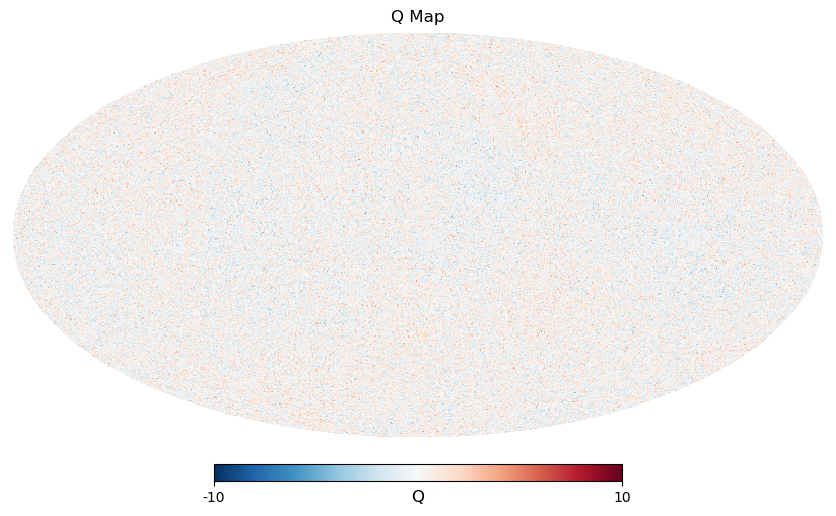

In [22]:
hp.mollview(Q, min=-10, max=10, unit=r'$\mathrm{Q}$', cmap='RdBu_r', title='Q Map')

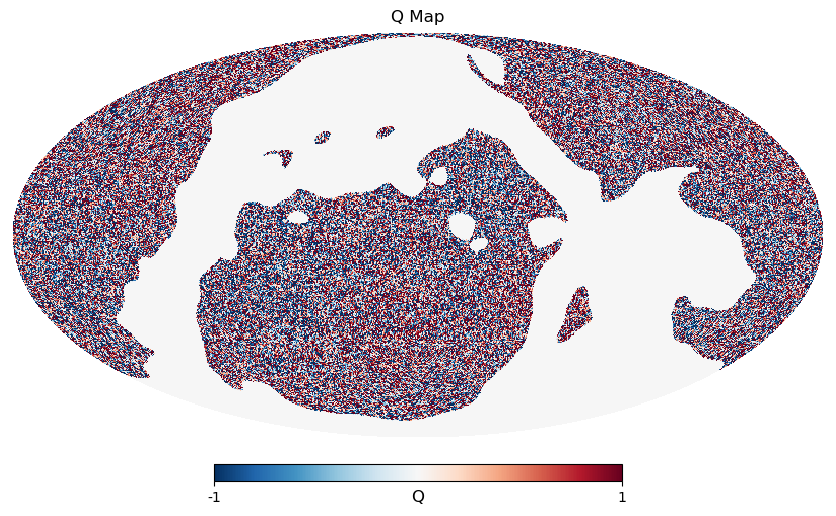

In [48]:
hp.mollview((s[1]+n)*m128, min=-1, max=1, unit=r'$\mathrm{Q}$', cmap='RdBu_r', title='Q Map')

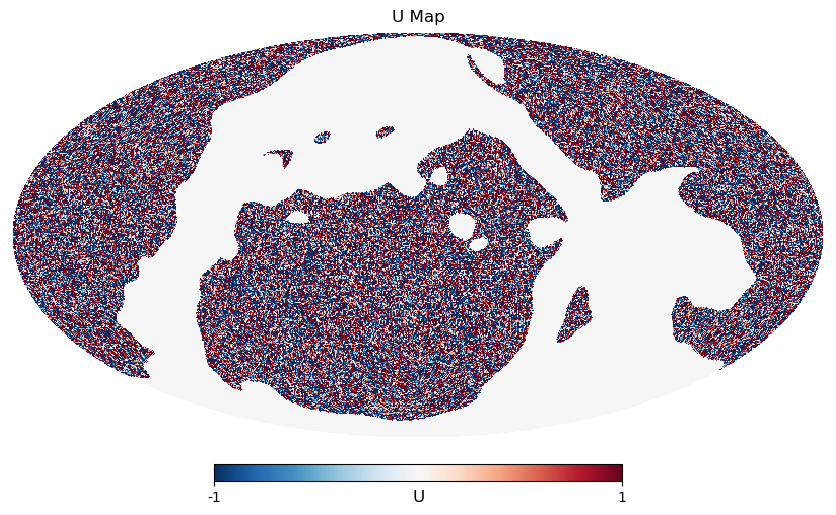

In [49]:
hp.mollview((s[1]+n-Q)*m128, min=-1, max=1, unit=r'$\mathrm{U}$', cmap='RdBu_r', title='U Map')

In [32]:
print(w1, w2)

[-0.01508452  1.0335979  -0.01851338] [-0.01865355  1.0366914  -0.01803784]


In [ ]:
'''
Anping's code
'''
from scipy.linalg import cho_factor, cho_solve
from scipy.sparse.linalg import LinearOperator, cg          # assumed (not visible)
from threadpoolctl import threadpool_limits                 # assumed (not visible)

# Globals defined elsewhere in the notebook:
# mask_ilc, nside_sim, nside_analysis, lmax_sim, nthreads, cl_true, pixel_area


def build_ilc_basis(cl_fid, lmax_pre=8):
    basis = np.empty((2 * mask_ilc.sum(), (lmax_pre + 1)**2 - 4), order="F") # creating matrix with one row per masked pixel outside galactic plane for Q and U, and one column per alm mode (except for ell=0,1)
    alms = np.zeros((2, hp.Alm.getsize(lmax_pre)), dtype=complex)
    column = 0

    for ell in range(2, lmax_pre + 1):
        for m in range(ell + 1):
            index = hp.Alm.getidx(lmax_pre, ell, m)
            amplitudes = ((1.,) if m == 0
                          else (1 / np.sqrt(2), 1j / np.sqrt(2)))
            for amplitude in amplitudes:
                alms[0, index] = amplitude * np.sqrt(cl_fid[1, ell]) # scales amplitude of alm by sqrt of fiducial EE power spectrum at ell
                qu = hp.alm2map_spin(alms, nside_sim, 2, lmax_pre) # converts the alms to Q and U maps at nside_sim with spin=2 and lmax=lmax_pre
                basis[:, column] = np.concatenate([q[mask_ilc] for q in qu]) # creates a column in the basis matrix with the Q and U values at the masked pixels for this particular alm mode
                alms[0, index] = 0 # reset for next iteration
                column += 1

    with threadpool_limits(limits=nthreads, user_api="blas"):
        gram = basis.T @ basis # pixel space covariance of large scale E modes
    return basis, gram


def make_ilc_inverse(variance, cl_fid, basis, gram):
    size = 2 * mask_ilc.sum() # length of the vectorized Q and U maps at the masked pixels
    spectra = cl_fid[1:3, :lmax_sim + 1] / hp.nside2pixarea(nside_sim) # dividing by pixel area that comes from map2alm??
    qu = np.zeros((2, hp.nside2npix(nside_sim)))

    def covariance_product(v): # computes Covariance @ v, where Covariance = S + N, with S being the signal covariance and N being the noise covariance
        qu[:, mask_ilc] = v.reshape(2, -1) # splits back into Q and U row for masked pixels
        alms = hp.map2alm_spin(qu, 2, lmax=lmax_sim) 
        signal = hp.alm2map_spin([hp.almxfl(a, cl) for a, cl in zip(alms, spectra)],
                                 nside_sim, 2, lmax_sim) # multiplies alm by Cl_EE and Cl_BB respectively, and converts back to Q and U maps at nside_sim
        return (np.concatenate([q[mask_ilc] for q in signal]) + variance * v.ravel()) # keeps only masked pixels and adds noise variance term (v.ravel)

    factor = cho_factor(gram + variance * np.eye(len(gram))) # Cholesky factorization

    def precondition(v):
        a = cho_solve(factor, basis.T @ v, check_finite=False) # gets best fit amplitude for each ell
        return (v - basis @ a) / variance # minimizing residuals

    covariance = LinearOperator((size, size), matvec=covariance_product, dtype=float)
    preconditioner = LinearOperator((size, size), matvec=precondition, dtype=float)

    def solve(rhs):
        result, info = cg(covariance, rhs, M=preconditioner, tol=1e-8, atol=0.0, maxiter=1000) # solving the linear system using conjugate gradient method with preconditioning
        if info != 0:
            raise RuntimeError(f"not converge {info}")
        return result

    return solve


ilc_basis, ilc_gram = build_ilc_basis(cl_true)


def make_ilc_solver(noise_level, ilc_model=None):
    if ilc_model is None:
        cl_fid, basis, gram = cl_true, ilc_basis, ilc_gram
    else:
        cl_fid, basis, gram = ilc_model

    reg_sigma = 0.02 * nside_sim / nside_analysis
    variance = 2 * noise_level**2 / pixel_area + reg_sigma**2
    solve = make_ilc_inverse(variance, cl_fid, basis, gram) # makes C^-1 solver
    inverse_D = None

    def get_weights(maps, split_difference):
        nonlocal inverse_D

        X = maps[:, 1:, :][:, :, mask_ilc].reshape(3, -1).T
        D = X[:, 1:] - X[:, :1]

        if inverse_D is None:
            Z = np.empty_like(D)
            columns = (0, 1)
        else:
            Z = inverse_D
            columns = (0,) if noise_level > 0 else ()

        for k in columns:
            Z[:, k] = solve(D[:, k])
        inverse_D = Z

        H = D.T @ Z
        if noise_level > 0:
            delta = split_difference[:, mask_ilc].ravel()
            H[0, 0] -= delta @ solve(delta)

        if np.linalg.eigvalsh(H)[0] <= 0:
            raise RuntimeError("fit not positive def.")

        coefficients = np.linalg.solve(H, -Z.T @ X[:, 0])
        return np.r_[1 - coefficients.sum(), coefficients]

    return get_weights

## Pixel-space ILC: math summary

**Notation.** $P$: select masked pixels · $Y$: spin-2 synthesis (E/B → Q/U) · $\Omega$: pixel area · $\mathbf{x}_\nu$: masked Q/U vector at frequency $\nu$ · $n = 2N_p$.

**1. Large-scale basis** (`build_ilc_basis`): one column per real E-mode, $2 \le \ell \le 8$:
$$
B = P\,Y_E^{(\ell\le 8)}\,\Lambda_{EE}^{1/2} \quad (n \times 77), \qquad G = B^\top B \quad (77\times 77), \qquad S_{\text{low}} = BB^\top
$$

**2. Covariance** (`covariance_product`), applied via harmonic transforms, never stored:
$$
C = P\,Y\,\mathrm{diag}(C_\ell^{EE}, C_\ell^{BB})\,Y^\top P^\top + \sigma^2 I,
\qquad \sigma^2 = \frac{2\sigma_{\text{noise}}^2}{\Omega_{\text{pix}}} + \sigma_{\text{reg}}^2
$$

**3. Preconditioner** (`precondition`), exact inverse of noise + large scales via Woodbury:
$$
M = (\sigma^2 I + BB^\top)^{-1} = \frac{1}{\sigma^2}\left[I - B(\sigma^2 I + G)^{-1}B^\top\right]
$$

**4. Solve** (`solve`): preconditioned CG for $C\mathbf{x} = \mathbf{b}$, stopping at $\|\mathbf{r}\| \le 10^{-8}\|\mathbf{b}\|$.

**5. ILC weights** (`get_weights`): with $D = [\mathbf{x}_1 - \mathbf{x}_0,\; \mathbf{x}_2 - \mathbf{x}_0]$ and $\mathbf{w} = (1 - c_1 - c_2,\, c_1,\, c_2)$, so $\sum w = 1$:
$$
\min_{\mathbf{c}}\; (\mathbf{x}_0 + D\mathbf{c})^\top C^{-1} (\mathbf{x}_0 + D\mathbf{c})
\;\;\Rightarrow\;\;
Z = C^{-1}D, \quad H = D^\top Z, \quad \mathbf{c} = -H^{-1} Z^\top \mathbf{x}_0
$$

**6. Noise debias**: $\boldsymbol{\delta}$ is a noise-only split difference.
$$
H_{00} \leftarrow H_{00} - \boldsymbol{\delta}^\top C^{-1}\boldsymbol{\delta}
$$
This assumes the noise enters only $\mathbf{x}_1$, which also justifies caching $Z_{:,1}$. The code then requires $\lambda_{\min}(H) > 0$.